In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")


In [4]:
file_path = Path(
    r"I:\Muzzamil Data Analyst\OBSIS Intership Project\OIBSIP DataAnalytics-L2-HousePricePrediction\data.csv"
)

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (4600, 18)


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [15]:
print("Dataset shape:", df.shape)

print("\nTarget variable summary:")
display(df["price"].describe())

print("\nMissing values:")
display(
    df.isnull().sum().sort_values(ascending=False).head(20)
)


Dataset shape: (4600, 18)

Target variable summary:


count    4.600000e+03
mean     5.519630e+05
std      5.638347e+05
min      0.000000e+00
25%      3.228750e+05
50%      4.609435e+05
75%      6.549625e+05
max      2.659000e+07
Name: price, dtype: float64


Missing values:


date             0
price            0
statezip         0
city             0
street           0
yr_renovated     0
yr_built         0
sqft_basement    0
sqft_above       0
condition        0
view             0
waterfront       0
floors           0
sqft_lot         0
sqft_living      0
bathrooms        0
bedrooms         0
country          0
dtype: int64

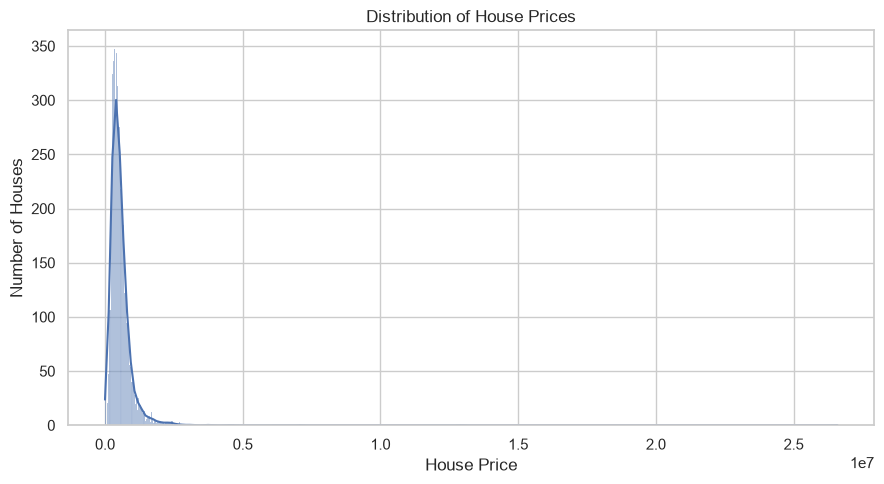

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="price", kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()


### Dataset Overview

The dataset contains 4,600 house records and 18 columns. The target variable is `price`, which represents the house price. The available features include bedrooms, bathrooms, living area, lot area, floors, waterfront status, view, property condition, year built, and location information.

These features may help explain differences in house prices. Exploratory Data Analysis (EDA) is used to understand the price distribution, identify missing values, and examine the relationships between property characteristics and prices.

In [20]:
print("Duplicate rows:", df.duplicated().sum())

print("Zero-price houses:", (df["price"] == 0).sum())

print("\nRows with zero price:")
display(df[df["price"] == 0].head())

print("\nHighest-priced houses:")
display(
    df.nlargest(5, "price")[
        ["price", "bedrooms", "bathrooms", "sqft_living", "city"]
    ]
)


Duplicate rows: 0
Zero-price houses: 49

Rows with zero price:


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
4354,2014-05-05 00:00:00,0.0,3.0,1.75,1490,10125,1.0,0,0,4,1490,0,1962,0,3911 S 328th St,Federal Way,WA 98001,USA
4356,2014-05-05 00:00:00,0.0,4.0,2.75,2600,5390,1.0,0,0,4,1300,1300,1960,2001,2120 31st Ave W,Seattle,WA 98199,USA
4357,2014-05-05 00:00:00,0.0,6.0,2.75,3200,9200,1.0,0,2,4,1600,1600,1953,1983,12271 Marine View Dr SW,Burien,WA 98146,USA
4358,2014-05-06 00:00:00,0.0,5.0,3.50,3480,36615,2.0,0,0,4,2490,990,1983,0,21809 SE 38th Pl,Issaquah,WA 98075,USA
4361,2014-05-07 00:00:00,0.0,5.0,1.50,1500,7112,1.0,0,0,5,760,740,1920,0,14901-14999 12th Ave SW,Burien,WA 98166,USA



Highest-priced houses:


,price,bedrooms,bathrooms,sqft_living,city
4350,26590000.0,3.0,2.00,1180,Kent
4346,12899000.0,3.0,2.50,2190,Seattle
2286,7062500.0,5.0,4.50,10040,Bellevue
2654,4668000.0,5.0,6.75,9640,Mercer Island
2761,4489000.0,4.0,3.00,6430,Bellevue


In [22]:

numerical_cols = [
    "price", "bedrooms", "bathrooms", "sqft_living",
    "sqft_lot", "floors", "view", "condition",
    "sqft_above", "sqft_basement", "yr_built",
    "yr_renovated", "waterfront"
]

display(df[numerical_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
price,4600.0,551962.988473,563834.702547,0.0,322875.00,460943.461539,654962.50,26590000.0
bedrooms,4600.0,3.400870,0.908848,0.0,3.00,3.000000,4.00,9.0
bathrooms,4600.0,2.160815,0.783781,0.0,1.75,2.250000,2.50,8.0
sqft_living,4600.0,2139.346957,963.206916,370.0,1460.00,1980.000000,2620.00,13540.0
sqft_lot,4600.0,14852.516087,35884.436145,638.0,5000.75,7683.000000,11001.25,1074218.0
floors,4600.0,1.512065,0.538288,1.0,1.00,1.500000,2.00,3.5
view,4600.0,0.240652,0.778405,0.0,0.00,0.000000,0.00,4.0
condition,4600.0,3.451739,0.677230,1.0,3.00,3.000000,4.00,5.0
sqft_above,4600.0,1827.265435,862.168977,370.0,1190.00,1590.000000,2300.00,9410.0
sqft_basement,4600.0,312.081522,464.137228,0.0,0.00,0.000000,610.00,4820.0


### Feature Selection and Reasoning

Potential predictors of house prices include living area, lot area, number of bedrooms and bathrooms, floors, waterfront status, view, property condition, year built, renovation year, and location.

Living area and lot area may reflect property size, while bedrooms and bathrooms describe capacity and layout. Waterfront status, view, condition, and location may capture differences in desirability. Property age and renovation history may also relate to value.

The `price` column is the target variable. It must not be included among the input features. The `date` column will be reviewed to determine whether extracting its year or month is useful. Categorical location fields such as `city` and `statezip` will require encoding before modeling.

In [25]:
zero_price_houses = df[df["price"] == 0]

print("Number of zero-price houses:", len(zero_price_houses))

display(
    zero_price_houses[
        ["price", "bedrooms", "bathrooms", "sqft_living",
         "sqft_lot", "city", "statezip"]
    ].head(15)
)

Number of zero-price houses: 49


,price,bedrooms,bathrooms,sqft_living,sqft_lot,city,statezip
4354,0.0,3.0,1.75,1490,10125,Federal Way,WA 98001
4356,0.0,4.0,2.75,2600,5390,Seattle,WA 98199
4357,0.0,6.0,2.75,3200,9200,Burien,WA 98146
4358,0.0,5.0,3.50,3480,36615,Issaquah,WA 98075
4361,0.0,5.0,1.50,1500,7112,Burien,WA 98166
4362,0.0,4.0,4.00,3680,18804,Sammamish,WA 98074
4374,0.0,2.0,2.50,2200,188200,Enumclaw,WA 98022
4376,0.0,4.0,2.25,2170,10500,Normandy Park,WA 98166
4382,0.0,5.0,4.50,4630,6324,Snoqualmie,WA 98065
4383,0.0,5.0,4.00,4430,9000,Bellevue,WA 98004


In [27]:
print("Zero-price houses by city:")
display(zero_price_houses["city"].value_counts().head(10))

print("\nLiving area statistics:")
print("Zero-price median:", zero_price_houses["sqft_living"].median())
print("All houses median:", df["sqft_living"].median())

print("\nPrice distribution:")
print(df["price"].quantile([0, 0.01, 0.25, 0.50, 0.75, 0.95, 0.99, 1]))

Zero-price houses by city:


city
Seattle             12
Bellevue             5
Sammamish            4
Mercer Island        4
Federal Way          3
Burien               2
Renton               2
Clyde Hill           2
Snoqualmie           2
Lake Forest Park     2
Name: count, dtype: int64


Living area statistics:
Zero-price median: 2600.0
All houses median: 1980.0

Price distribution:
0.00    0.000000e+00
0.01    0.000000e+00
0.25    3.228750e+05
0.50    4.609435e+05
0.75    6.549625e+05
0.95    1.184050e+06
0.99    2.005220e+06
1.00    2.659000e+07
Name: price, dtype: float64


In [29]:
df_model = df[df["price"] > 0].copy()

print("Original dataset shape:", df.shape)
print("Modeling dataset shape:", df_model.shape)
print("Remaining zero-price records:", (df_model["price"] == 0).sum())
print("Missing values:", df_model.isnull().sum().sum())

Original dataset shape: (4600, 18)
Modeling dataset shape: (4551, 18)
Remaining zero-price records: 0
Missing values: 0


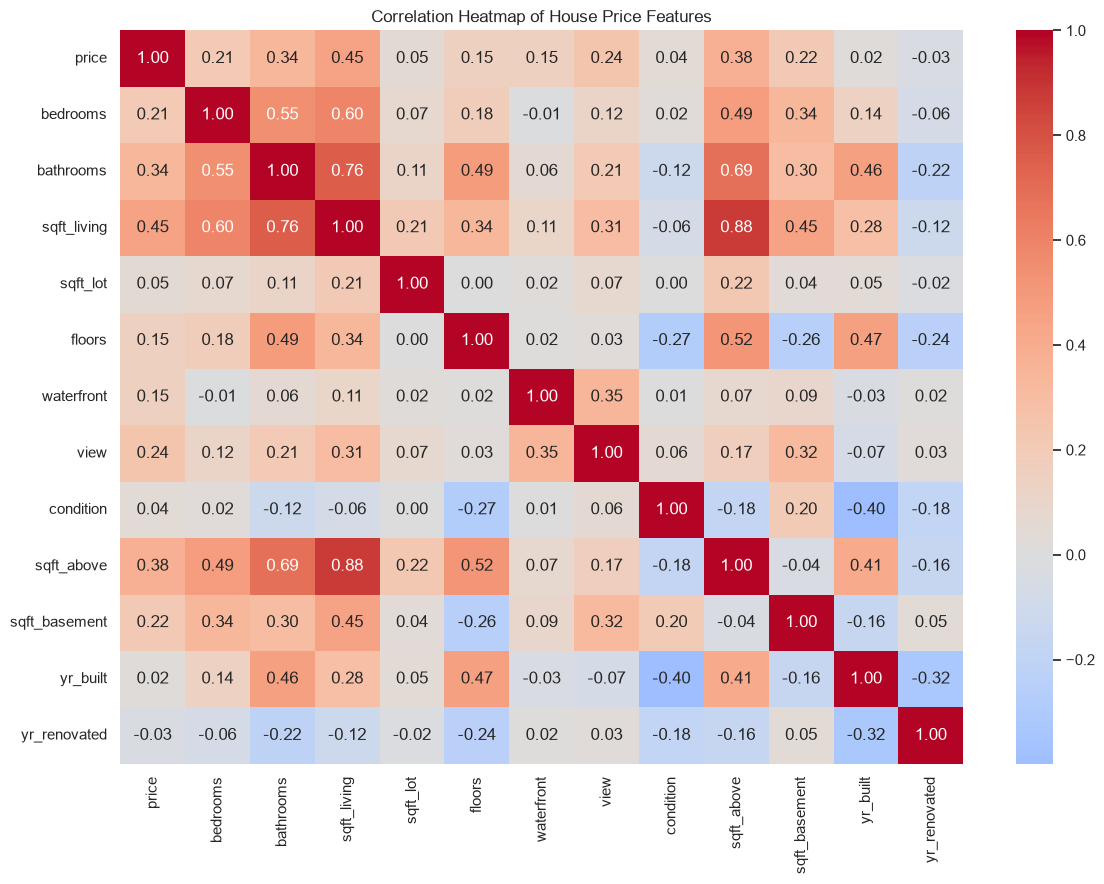

Features most positively correlated with price:


sqft_living      0.445494
sqft_above       0.380661
bathrooms        0.341126
view             0.242587
sqft_basement    0.217782
bedrooms         0.210228
floors           0.152758
waterfront       0.150083
sqft_lot         0.051347
condition        0.038892
Name: price, dtype: float64

In [31]:
numeric_df = df_model.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of House Price Features")
plt.tight_layout()
plt.show()

print("Features most positively correlated with price:")
display(
    correlation["price"]
    .sort_values(ascending=False)
    .drop("price")
    .head(10)
)

In [33]:

target = "price"

numerical_features = [
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "waterfront",
    "view",
    "condition",
    "sqft_above",
    "sqft_basement",
    "yr_built",
    "yr_renovated"
]

categorical_features = [
    "city",
    "statezip",
    "country"
]

features = numerical_features + categorical_features

X = df_model[features]
y = df_model[target]

print("Number of features before encoding:", len(features))
print("X shape:", X.shape)
print("y shape:", y.shape)


Number of features before encoding: 15
X shape: (4551, 15)
y shape: (4551,)


In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 3640
Testing samples: 911


In [37]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


In [39]:

from sklearn.linear_model import LinearRegression

linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")


Linear Regression model trained successfully.


In [41]:

from sklearn.metrics import mean_squared_error, r2_score

y_pred = linear_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")


Mean Squared Error (MSE): 54,014,042,107.23
Root Mean Squared Error (RMSE): 232,409.21
R² Score: 0.6369


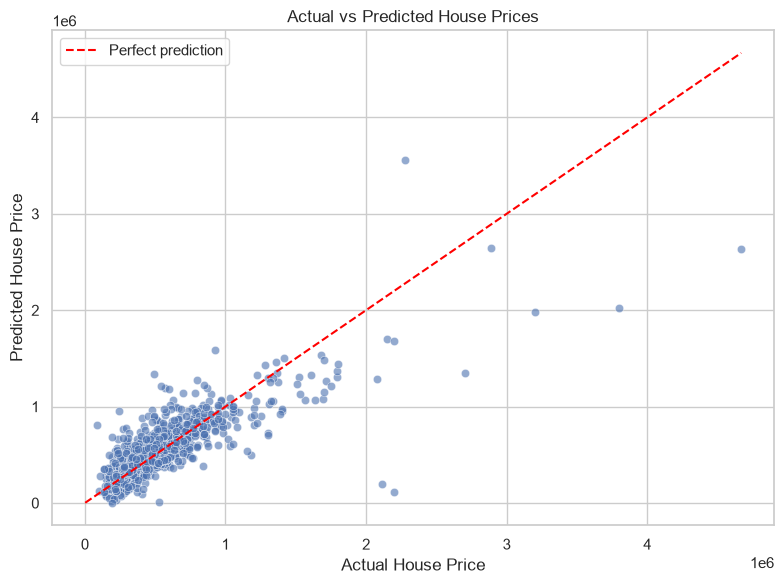

In [43]:

plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    color="red",
    label="Perfect prediction"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.tight_layout()
plt.show()


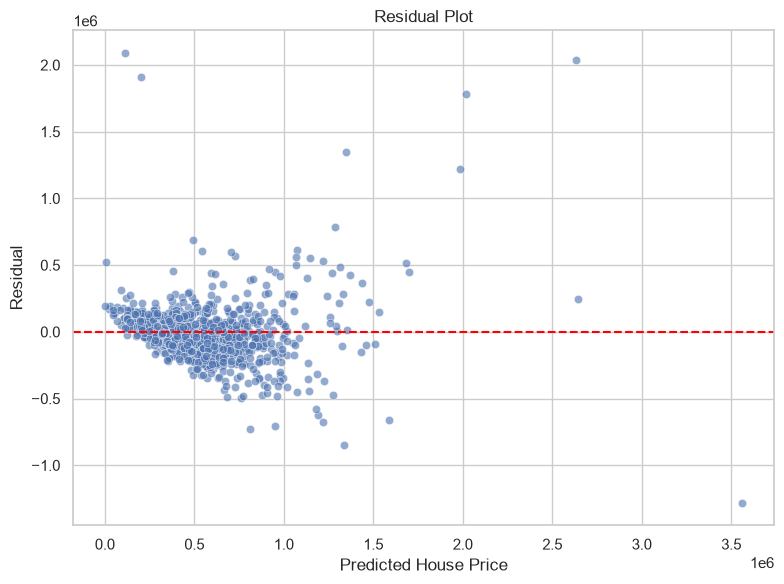

In [45]:

residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_pred, y=residuals, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted House Price")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()


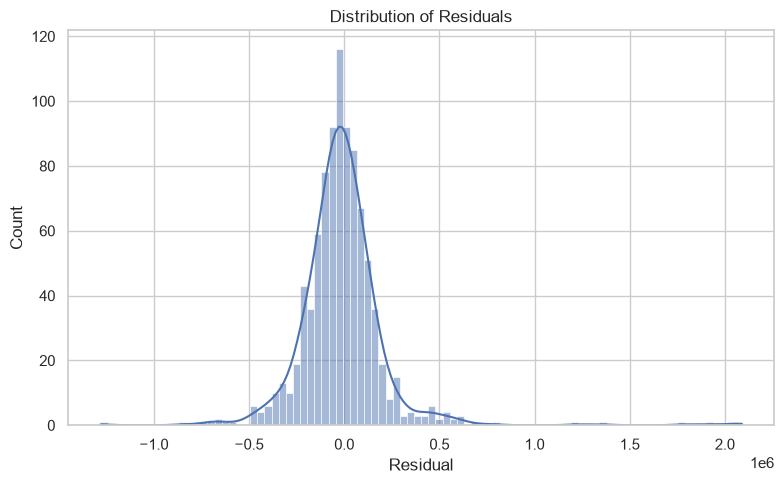

Mean residual: -11513.24


In [47]:

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.title("Distribution of Residuals")
plt.xlabel("Residual")
plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 2))


In [49]:

fitted_preprocessor = linear_model.named_steps["preprocessor"]
fitted_regression = linear_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_regression.coef_

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

print("Top 10 positive coefficients:")
display(
    coef_df.sort_values("Coefficient", ascending=False).head(10)
)

print("\nTop 10 negative coefficients:")
display(
    coef_df.sort_values("Coefficient", ascending=True).head(10)
)


Top 10 positive coefficients:


,Feature,Coefficient
45,cat__city_Seattle,154952.269163
1,num__bathrooms,107762.684964
14,cat__city_Bellevue,102524.578447
57,cat__statezip_WA 98004,92148.850487
7,num__condition,91051.968875
6,num__view,62888.738897
128,cat__statezip_WA 98199,56593.248779
73,cat__statezip_WA 98031,54691.006188
107,cat__statezip_WA 98112,51137.518656
79,cat__statezip_WA 98040,51092.773906



Top 10 negative coefficients:


,Feature,Coefficient
42,cat__city_Renton,-77917.304905
25,cat__city_Federal Way,-68651.776405
13,cat__city_Auburn,-68017.834670
67,cat__statezip_WA 98023,-44784.228391
0,num__bedrooms,-42040.522941
80,cat__statezip_WA 98042,-36244.469256
99,cat__statezip_WA 98092,-32689.373828
31,cat__city_Maple Valley,-31494.561344
77,cat__statezip_WA 98038,-31494.561344
90,cat__statezip_WA 98058,-31150.032257


In [51]:

from sklearn.linear_model import Ridge
from sklearn.base import clone

ridge_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

print("Ridge Regression trained successfully.")


Ridge Regression trained successfully.


In [53]:

comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    },
    {
        "Model": "Ridge Regression",
        "MSE": mean_squared_error(y_test, ridge_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, ridge_pred)),
        "R2 Score": r2_score(y_test, ridge_pred)
    }
])

display(comparison.round(4))


,Model,MSE,RMSE,R2 Score
0,Linear Regression,5.401404e+10,232409.2126,0.6369
1,Ridge Regression,6.836537e+10,261467.7151,0.5405


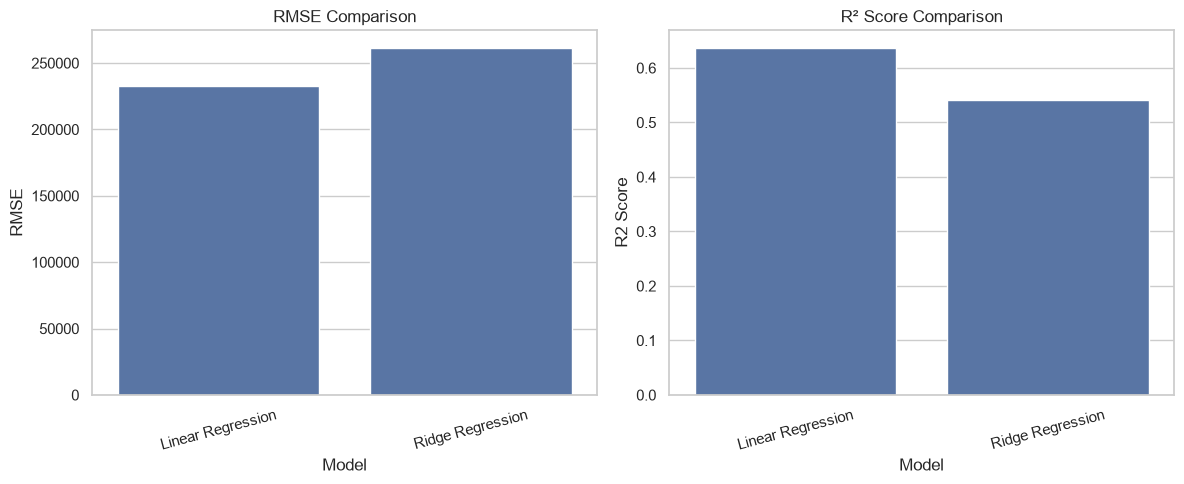

In [55]:

comparison_plot = comparison.melt(
    id_vars="Model",
    value_vars=["RMSE", "R2 Score"],
    var_name="Metric",
    value_name="Score"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="RMSE",
    ax=axes[0]
)
axes[0].set_title("RMSE Comparison")
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(
    data=comparison,
    x="Model",
    y="R2 Score",
    ax=axes[1]
)
axes[1].set_title("R² Score Comparison")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


In [57]:
display(comparison.round(4))

,Model,MSE,RMSE,R2 Score
0,Linear Regression,5.401404e+10,232409.2126,0.6369
1,Ridge Regression,6.836537e+10,261467.7151,0.5405


## Conclusion

In this project, I developed a house-price prediction model using Python, pandas, and scikit-learn. The dataset contained 4,600 records and 18 columns. During data exploration, I identified 49 records with zero house prices and excluded them from modeling because zero was not a meaningful target value for this prediction task.

I selected numerical property characteristics and categorical location features as predictors. Categorical variables were encoded using One-Hot Encoding, and a preprocessing pipeline was used to prepare the features. The data was split into 80% training and 20% testing sets.

The Linear Regression model achieved an MSE of 54,014,042,107.23, an RMSE of 232,409.21, and an R² score of 0.6369. This indicates that the model explained approximately 63.69% of the variation in house prices in the test dataset.

I also tested Ridge Regression with a regularization parameter of alpha = 1.0. It achieved an RMSE of 261,467.72 and an R² score of 0.5405. Therefore, Linear Regression performed better than Ridge Regression under the tested settings.

The actual-versus-predicted plot, residual analysis, correlation heatmap, and coefficient analysis helped evaluate model behavior and identify relationships between house features and prices.

This project demonstrates how regression models can support preliminary property-price estimation. However, prediction errors remain substantial, and the results may be affected by extreme prices, data quality, and features not included in the model. Further work could involve tuning Ridge regularization, investigating unusual records, engineering additional features, and testing more advanced regression models.